# Table of Contents
- 1. Two-Sample Z-Tests and T-Tests for Proportions/Means
- 2. Chi-Square Tests for Categorical Conversion Rates
- 3. Calculating P-Values and Confidence Intervals for Uplift
- 4. Handling Multiple Testing Corrections (Bonferroni, FDR)

In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"]

print("Global libraries for hypothesis testing in A/B tests loaded successfully.")

Global libraries for hypothesis testing in A/B tests loaded successfully.


---
## 1. Two-Sample Z-Tests and T-Tests for Proportions/Means

### 1. Definition
Two-sample hypothesis tests evaluate whether the difference between control and treatment group metrics (proportions or continuous means) is statistically significant or merely a result of random sampling noise.

### 2. Math Formula
Z-test statistic for independent proportions $p_1$ and $p_2$ with pooled proportion $\bar{p}$ and sample sizes $n_1, n_2$:
$$Z = \frac{p_1 - p_2}{\sqrt{\bar{p}(1 - \bar{p}) \left( \frac{1}{n_1} + \frac{1}{n_2} \right)}}$$

### 3. Notation Pronunciation
- `proportions_ztest()`: "Two-proportion binomial z-test utility"
- $\bar{p}$: "Pooled sample conversion proportion"

### 4. Naive Example
Testing whether a checkout redesign converted 12.5% of visitors compared to the control group's 11.0% with 10,000 users each.
### 5. Uses
Analyzing binary conversion rates and click-through rates in A/B tests.
- Comparing average order values between control and treatment.
- Validating product feature impact.

Z-Statistic: -3.294 | P-Value: 0.0010


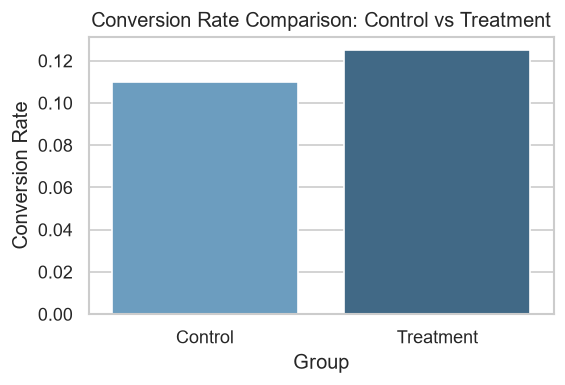

In [3]:
# 6. & 7. Implementation and Visualization
count = np.array([1100, 1250]) # Conversions
nobs = np.array([10000, 10000]) # Sample sizes
z_stat, p_val = proportions_ztest(count, nobs)
print(f"Z-Statistic: {z_stat:.3f} | P-Value: {p_val:.4f}")

# Visualization
df_rates = pd.DataFrame({
    'Group': ['Control', 'Treatment'],
    'Conversion_Rate': [count[0]/nobs[0], count[1]/nobs[1]]
})
plt.figure(figsize=(5, 3))
sns.barplot(x='Group', y='Conversion_Rate', hue='Group', data=df_rates, palette='Blues_d', legend=False, errorbar=None)
plt.title('Conversion Rate Comparison: Control vs Treatment')
plt.ylabel('Conversion Rate')
plt.show()

---
## 2. Chi-Square Tests for Categorical Conversion Rates

### 1. Definition
The Chi-Square test of independence examines contingency tables to determine whether categorical outcome distributions (e.g., converted, bounced, abandoned) differ significantly across experimental variants.

### 2. Math Formula
Chi-square test statistic $\chi^2$ comparing observed frequencies $O_{ij}$ against expected frequencies $E_{ij}$:
$$\chi^2 = \sum_{i} \sum_{j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

### 3. Notation Pronunciation
- `chi2_contingency()`: "Categorical cross-tabulation independence test"
- $E_{ij}$: "Expected frequency under independence null hypothesis"

### 4. Naive Example
Evaluating multi-class user funnel outcomes (Home, Cart, Purchase) across three different website layout variants.
### 5. Uses
- Analyzing multi-category user behavior and conversion funnels.
- Testing independence between user segments and variant responses.
- Checking sample ratio mismatches (SRM).

Chi2 Statistic: 10.705 | P-Value: 0.0011


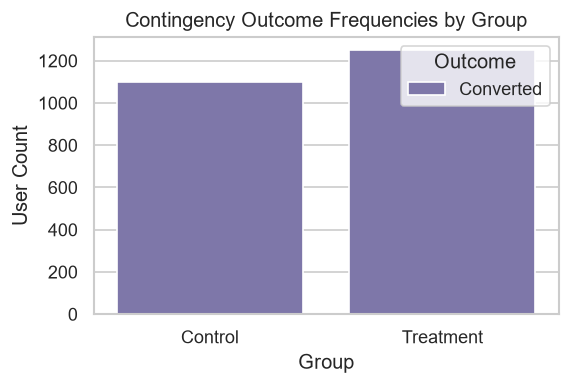

In [4]:
# 6. & 7. Implementation and Visualization
contingency_table = [[8900, 1100], [8750, 1250]] # [Control, Treatment] x [Non-converted, Converted]
chi2, p_chi2, dof, ex = chi2_contingency(contingency_table)
print(f"Chi2 Statistic: {chi2:.3f} | P-Value: {p_chi2:.4f}")

# Visualization
df_chi = pd.DataFrame({'Outcome': ['Converted', 'Converted'], 'Group': ['Control', 'Treatment'], 'Count': [1100, 1250]})
plt.figure(figsize=(5, 3))
sns.barplot(x='Group', y='Count', hue='Outcome', data=df_chi, palette='Purples_d', errorbar=None)
plt.title('Contingency Outcome Frequencies by Group')
plt.ylabel('User Count')
plt.show()

---
## 3. Calculating P-Values and Confidence Intervals for Uplift

### 1. Definition
Calculating p-values quantifies the probability of observing results as extreme under the null hypothesis, while confidence intervals for uplift provide a range of plausible business impact values.

### 2. Math Formula
Absolute uplift $\Delta = p_t - p_c$ with standard error $SE_{\Delta}$ and 95% confidence interval:
$$CI_{95\%} = (p_t - p_c) \pm 1.96 \cdot \sqrt{\frac{p_c(1-p_c)}{n_c} + \frac{p_t(1-p_t)}{n_t}}$$

### 3. Notation Pronunciation
- `Uplift CI`: "Range of plausible true percentage gain from treatment"
- `P-Value`: "Evidence strength against the null hypothesis of zero effect"

### 4. Naive Example
Reporting a conversion uplift of +1.5% with a 95% confidence interval of $[+0.8\%, +2.2\%]$, confirming zero is excluded.
### 5. Uses
- Communicating business ROI and financial impact to stakeholders.
- Assessing practical significance alongside statistical significance.
- Making data-driven rollout decisions.

Absolute Uplift: 0.0150 | 95% CI: [0.0061, 0.0239]


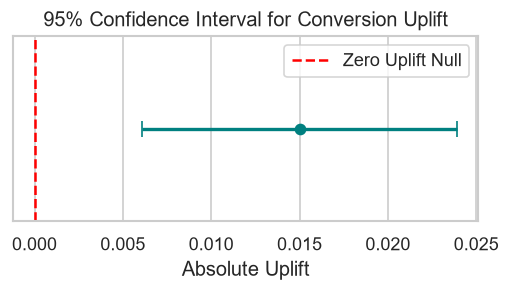

In [5]:
# 6. & 7. Implementation and Visualization
pc, pt = 0.11, 0.125
nc, nt = 10000, 10000
uplift = pt - pc
se_uplift = np.sqrt((pc*(1-pc)/nc) + (pt*(1-pt)/nt))
ci_lower, ci_upper = uplift - 1.96 * se_uplift, uplift + 1.96 * se_uplift
print(f"Absolute Uplift: {uplift:.4f} | 95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

# Visualization
df_ci = pd.DataFrame({'Metric': ['Uplift Estimate'], 'Value': [uplift], 'Lower': [ci_lower], 'Upper': [ci_upper]})
plt.figure(figsize=(5, 2))
plt.errorbar(x=[uplift], y=[0], xerr=[[uplift - ci_lower], [ci_upper - uplift]], fmt='o', color='teal', capsize=5, lw=2)
plt.axvline(x=0, color='red', linestyle='--', label='Zero Uplift Null')
plt.title('95% Confidence Interval for Conversion Uplift')
plt.xlabel('Absolute Uplift')
plt.yticks([])
plt.legend()
plt.show()

---
## 4. Handling Multiple Testing Corrections (Bonferroni, FDR)

### 1. Definition
When evaluating multiple metrics or variants simultaneously, the family-wise error rate (FWER) inflates; multiple testing corrections like Bonferroni or False Discovery Rate (FDR) adjust significance thresholds to prevent false positives.

### 2. Math Formula
Bonferroni corrected significance threshold $\alpha_{adj}$ across $m$ simultaneous hypothesis tests:
$$\alpha_{adj} = \frac{\alpha}{m}$$

### 3. Notation Pronunciation
- `Bonferroni Correction`: "Conservative alpha adjustment dividing threshold by test count $m$"
- `False Discovery Rate (FDR)`: "Controlling the proportion of false positives among rejected hypotheses"

### 4. Naive Example
Testing 10 different secondary metrics simultaneously and lowering the significance threshold from 0.05 to 0.005 to avoid false discoveries.
### 5. Uses
- Analyzing experiments with multiple secondary metrics and subgroups.
- Preventing false positive error inflation in large feature dashboards.
- Maintaining statistical integrity in complex A/B testing platforms.

Original Alpha: 0.05 | Bonferroni Adjusted Alpha (5 tests): 0.01


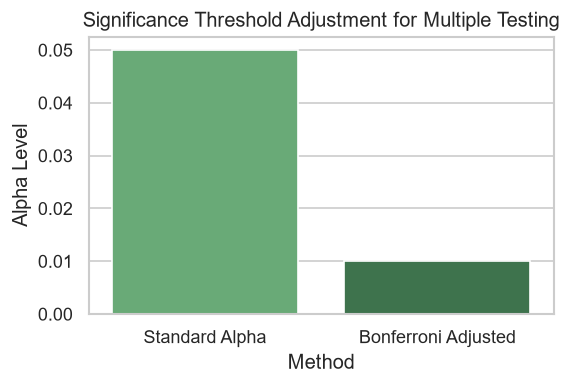

In [6]:
# 6. & 7. Implementation and Visualization
alpha_orig = 0.05
num_tests = 5
bonferroni_alpha = alpha_orig / num_tests
print(f"Original Alpha: {alpha_orig} | Bonferroni Adjusted Alpha ({num_tests} tests): {bonferroni_alpha}")

# Visualization
df_corr = pd.DataFrame({'Method': ['Standard Alpha', 'Bonferroni Adjusted'], 'Alpha': [alpha_orig, bonferroni_alpha]})
plt.figure(figsize=(5, 3))
sns.barplot(x='Method', y='Alpha', hue='Method', data=df_corr, palette='Greens_d', legend=False, errorbar=None)
plt.title('Significance Threshold Adjustment for Multiple Testing')
plt.ylabel('Alpha Level')
plt.show()

---
## Summary Table

| Hypothesis Testing Technique | Core Statistical Formula | Primary Business Objective | Analytical Advantage |
| :--- | :--- | :--- | :--- |
| **Z-Tests & T-Tests** | $Z = \frac{p_1 - p_2}{\sqrt{...}}$ | Comparing two conversion rates or means | Standard parametric evaluation of A/B test lift |
| **Chi-Square Tests** | $\chi^2 = \sum \frac{(O - E)^2}{E}$ | Evaluating multi-class categorical outcomes | Handles multi-variant and multi-funnel outcome frequencies |
| **P-Values & Uplift CIs** | $CI = \Delta \pm 1.96 \cdot SE$ | Quantifying business impact and significance | Provides plausible range of business value alongside p-values |
| **Multiple Testing Corrections** | $\alpha_{adj} = \frac{\alpha}{m}$ (Bonferroni) | Controlling false positive inflation | Prevents false discoveries when testing multiple metrics simultaneously |